# Comparacion de fuentes internacionales
Este notebook muestra que fuentes son comparables y cuales requieren transformaciones o deben mantenerse separadas.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / 'data').exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
RESULTS = PROJECT_ROOT / 'data' / '03_analysis_output' / 'comparacion_fuentes'
profile = pd.read_csv(RESULTS / 'perfil_comparativo_fuentes.csv')
matrix = pd.read_csv(RESULTS / 'matriz_comparabilidad.csv')
display(profile)
display(matrix)

,ciudad,fuente,metrica_principal,familia_metrica,unidad_conceptual,interpretacion,observaciones,media_valor_principal,minimo_valor_principal,maximo_valor_principal,fecha_minima,fecha_maxima,dias_observados,horas_observadas,comparacion_directa,condicion_comparacion
0,Istanbul,istanbul_traffic_index,indice_congestion,indice_congestion,indice relativo,nivel de congestion reportado por la fuente,3332,27.830846,1.083916,59.428571,2015-08-06,2024-10-18,3332,1,False,no comparar en escala original
1,Los Angeles County,metr_la,velocidad_sensor,velocidad,velocidad de sensor,velocidad observada por sensor,7094304,53.719021,0.000000,70.000000,2012-03-01,2012-06-27,119,24,True,verificar unidad y alinear ventana temporal
2,Madrid,madrid_traffic_points,intensidad,intensidad,intensidad de trafico,intensidad reportada por punto de trafico,12512133,366.029942,0.000000,26327.000000,2022-12-01,2022-12-31,31,24,False,no comparar en escala original
3,San Francisco Bay Area,pems_bay,velocidad_sensor,velocidad,velocidad de sensor,velocidad observada por sensor,16937700,62.619574,0.000000,85.100000,2017-01-01,2017-06-30,181,24,True,verificar unidad y alinear ventana temporal
4,Sao Paulo,sao_paulo_cet,congestion_longitud_m,congestion_longitud,longitud congestionada,longitud de congestion reportada por la fuente,5223411,1453.528826,51.000000,23200.000000,2001-01-02,2018-09-30,6094,24,False,no comparar en escala original


,ciudad,fuente,metrica_principal,familia_metrica,unidad_conceptual,comparacion_directa,condicion_comparacion
0,Sao Paulo,sao_paulo_cet,congestion_longitud_m,congestion_longitud,longitud congestionada,False,no comparar en escala original
1,Istanbul,istanbul_traffic_index,indice_congestion,indice_congestion,indice relativo,False,no comparar en escala original
2,Madrid,madrid_traffic_points,intensidad,intensidad,intensidad de trafico,False,no comparar en escala original
3,Los Angeles County,metr_la,velocidad_sensor,velocidad,velocidad de sensor,True,verificar unidad y alinear ventana temporal
4,San Francisco Bay Area,pems_bay,velocidad_sensor,velocidad,velocidad de sensor,True,verificar unidad y alinear ventana temporal


In [2]:
comparison_counts = profile.groupby(['familia_metrica', 'comparacion_directa'], as_index=False).size()
display(comparison_counts)
display(profile[['fuente', 'metrica_principal', 'unidad_conceptual', 'condicion_comparacion']])

,familia_metrica,comparacion_directa,size
0,congestion_longitud,False,1
1,indice_congestion,False,1
2,intensidad,False,1
3,velocidad,True,2


,fuente,metrica_principal,unidad_conceptual,condicion_comparacion
0,istanbul_traffic_index,indice_congestion,indice relativo,no comparar en escala original
1,metr_la,velocidad_sensor,velocidad de sensor,verificar unidad y alinear ventana temporal
2,madrid_traffic_points,intensidad,intensidad de trafico,no comparar en escala original
3,pems_bay,velocidad_sensor,velocidad de sensor,verificar unidad y alinear ventana temporal
4,sao_paulo_cet,congestion_longitud_m,longitud congestionada,no comparar en escala original


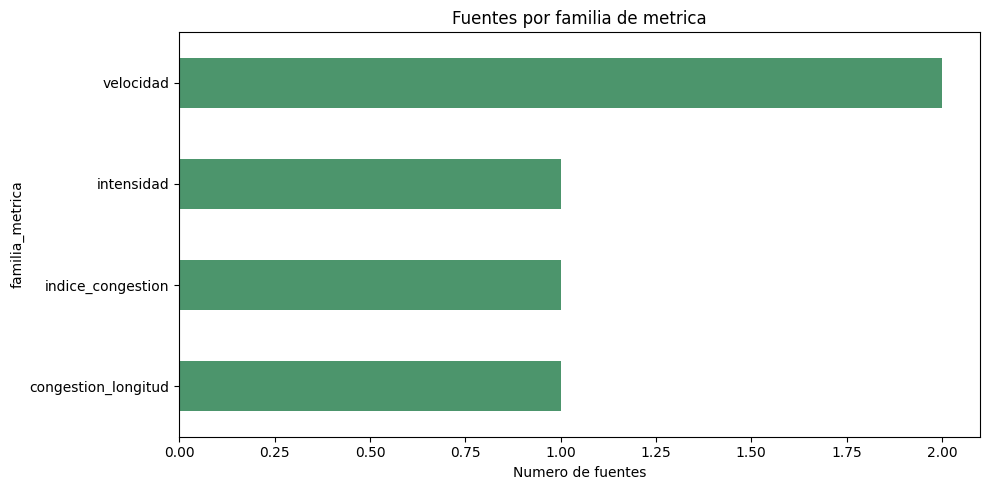

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
profile.assign(valor=1).groupby('familia_metrica')['valor'].sum().sort_values().plot.barh(ax=ax, color='#4c956c')
ax.set_title('Fuentes por familia de metrica')
ax.set_xlabel('Numero de fuentes')
plt.tight_layout()
plt.show()

## Decision analitica
La comparacion directa se limita a fuentes con la misma familia y unidad conceptual. Las demas se analizan dentro de su propia escala y no se mezclan sin una transformacion justificada.